# Spark vs Ray — Benchmark Analysis
**DA3408 Assignment 3.** Loads the metrics written by `spark_clean.py` / `ray_clean.py` (`results/*_runs.jsonl`)
and the resource samples from `monitor/record_stats.sh` (`results/*_stats_*.csv`), and produces the report figures.

Every number here comes from a real cluster run — nothing is typed in by hand.

In [1]:
import glob, json, subprocess
import pandas as pd
import matplotlib.pyplot as plt

SPARK, RAY = "#2a78d6", "#eb6834"          # categorical slots 1-2 (blue, orange)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COLORS = {"spark": SPARK, "ray": RAY}
# each script stamps run_ts in its container clock: Spark containers use UTC, the rayproject image uses US Pacific
RUN_TZ = {"spark": "UTC", "ray": "America/Los_Angeles"}

## 1. Load the benchmark runs (6 months, 20,332,093 raw rows)

In [2]:
rows = []
for engine in ("spark", "ray"):
    for i, line in enumerate(open(f"results/{engine}_runs.jsonl"), 1):
        d = json.loads(line)
        if d["months"] != "1-6":
            continue
        rows.append({"engine": engine, "run": i, "run_ts": d["run_ts"], **d["stage_sec"],
                     "total": d["total_sec"], **{f"udf_{k}": v for k, v in d.get("udf_sec", {}).items()},
                     **{f"rows_{k}": v for k, v in d["rows"].items()}})
runs = pd.DataFrame(rows)
runs.round(2)

,engine,run,run_ts,ingest,cleanse,transform,export,total,udf_native,udf_python_udf,rows_raw,rows_cleaned,rows_transformed
0,spark,1,2026-10-04 06:39:36,7.61,46.44,83.15,22.35,159.73,2.17,12.74,20332093,17870679,17865181
1,spark,2,2026-10-04 06:50:09,5.89,20.16,79.24,21.38,126.75,2.81,13.76,20332093,17870679,17865181
2,spark,3,2026-10-04 06:56:58,6.62,24.49,84.22,27.83,143.31,2.22,9.22,20332093,17870679,17865181
3,ray,1,2026-10-04 12:37:45,5.86,49.22,796.63,335.92,1187.64,1.88,15.57,20332093,17870679,17865181
4,ray,2,2026-10-04 13:12:25,7.50,42.43,733.91,301.23,1085.07,1.61,6.02,20332093,17870679,17865181
5,ray,3,2026-10-04 13:31:20,2.34,26.35,751.42,264.18,1044.29,1.55,5.82,20332093,17870679,17865181


## 2. Median of the runs — execution time and UDF overhead

In [3]:
STAGES = ["ingest", "cleanse", "transform", "export"]
med = runs.groupby("engine")[STAGES + ["total", "udf_native", "udf_python_udf"]].median().loc[["spark", "ray"]]
med["udf_overhead"] = med["udf_python_udf"] - med["udf_native"]
med["overhead_pct"] = 100 * med["udf_overhead"] / med["udf_python_udf"]
spread = runs.groupby("engine")["total"].agg(["min", "max"]).loc[["spark", "ray"]]
display(med.round(2)); display(spread.round(1))

,ingest,cleanse,transform,export,total,udf_native,udf_python_udf,udf_overhead,overhead_pct
engine,,,,,,,,,
spark,6.62,24.49,83.15,22.35,143.31,2.22,12.74,10.52,82.57
ray,5.86,42.43,751.42,301.23,1085.07,1.61,6.02,4.41,73.21


,min,max
engine,,
spark,126.8,159.7
ray,1044.3,1187.6


### Figure 1 — Where the time goes (median stage times)
Same pipeline, same 2 × (2 CPU, 3 GB) workers.

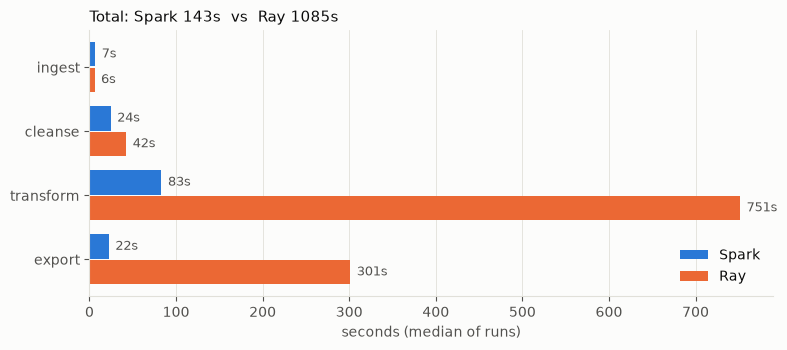

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = range(len(STAGES))
h = 0.38
for k, eng in enumerate(["spark", "ray"]):
    vals = med.loc[eng, STAGES].values
    pos = [p + (k - 0.5) * (h + 0.02) for p in y]
    ax.barh(pos, vals, height=h, color=COLORS[eng], label=eng.capitalize())
    for p, v in zip(pos, vals):
        ax.text(v + max(med[STAGES].max()) * 0.01, p, f"{v:.0f}s", va="center", fontsize=9, color=INK2)
ax.set_yticks(list(y)); ax.set_yticklabels(STAGES); ax.invert_yaxis()
ax.set_xlabel("seconds (median of runs)"); ax.grid(axis="y", visible=False)
ax.set_title(f"Total: Spark {med.loc['spark','total']:.0f}s  vs  Ray {med.loc['ray','total']:.0f}s", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig("report/figures/fig1_stage_times.png", dpi=200); plt.show()

### Figure 2 — The UDF deep-dive
The same speed rule computed natively (Spark: JVM expression; Ray: vectorised pandas) and as the row-at-a-time
Python function. The gap between the two bars is the cost of running custom Python.

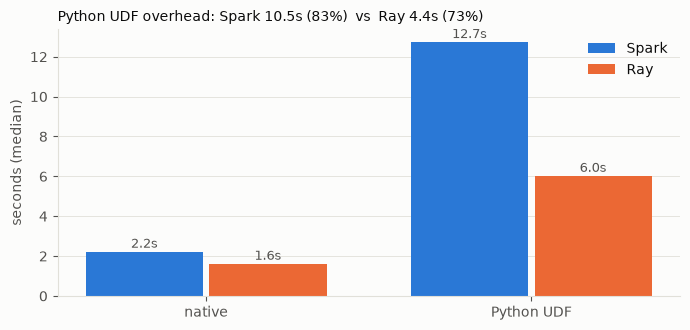

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4))
labels = ["native", "Python UDF"]
x = range(2); w = 0.36
for k, eng in enumerate(["spark", "ray"]):
    vals = [med.loc[eng, "udf_native"], med.loc[eng, "udf_python_udf"]]
    pos = [p + (k - 0.5) * (w + 0.02) for p in x]
    ax.bar(pos, vals, width=w, color=COLORS[eng], label=eng.capitalize())
    for p, v in zip(pos, vals):
        ax.text(p, v + 0.2, f"{v:.1f}s", ha="center", fontsize=9, color=INK2)
ax.set_xticks(list(x)); ax.set_xticklabels(labels); ax.set_ylabel("seconds (median)"); ax.grid(axis="x", visible=False)
ax.set_title(f"Python UDF overhead: Spark {med.loc['spark','udf_overhead']:.1f}s ({med.loc['spark','overhead_pct']:.0f}%)"
             f"  vs  Ray {med.loc['ray','udf_overhead']:.1f}s ({med.loc['ray','overhead_pct']:.0f}%)", loc="left", fontsize=10)
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("report/figures/fig2_udf.png", dpi=200); plt.show()

## 3. Resource utilisation (`docker stats`, ~2 s samples)
CPU % is per core, so a 2-CPU worker peaks at 200 %. Each run's window is [start, start + total].

In [6]:
def to_gib(s):
    return float(s[:-3]) / 1024 if s.endswith("MiB") else float(s[:-3]) if s.endswith("GiB") else float(s[:-2]) / 1024**2

stats = []
for f in sorted(glob.glob("results/*_stats_*.csv")):
    d = pd.read_csv(f); d["engine"] = f.split("/")[-1].split("_")[0]; stats.append(d)
stats = pd.concat(stats)
stats["mem_gib"] = stats["mem_used"].map(to_gib)
stats["role"] = stats["container"].map(lambda c: "coordinator" if ("master" in c or "head" in c) else "worker")

peaks = []
for _, r in runs.iterrows():
    t0 = pd.Timestamp(r["run_ts"], tz=RUN_TZ[r["engine"]]).timestamp(); t1 = t0 + r["total"]
    w = stats[(stats.engine == r.engine) & stats.timestamp.between(t0, t1)]
    for c, g in w.groupby("container"):
        peaks.append({"engine": r.engine, "run": r.run, "container": c, "role": g.role.iloc[0],
                      "peak_cpu_pct": g.cpu_percent.max(), "peak_mem_gib": g.mem_gib.max(),
                      "mean_cpu_pct": g.cpu_percent.mean()})
peaks = pd.DataFrame(peaks)
peak_tbl = peaks.groupby(["engine", "role"])[["peak_cpu_pct", "mean_cpu_pct", "peak_mem_gib"]].median()
peak_tbl.round(2)

peak_cpu_pct  mean_cpu_pct  peak_mem_gib
engine role                                                 
ray    coordinator         91.53         25.68          1.40
       worker             211.24         57.18          2.82
spark  coordinator        259.70         17.10          1.11
       worker             207.44        174.05          2.66

### Figure 3 — Worker memory during run 1 (cap = 3 GiB)

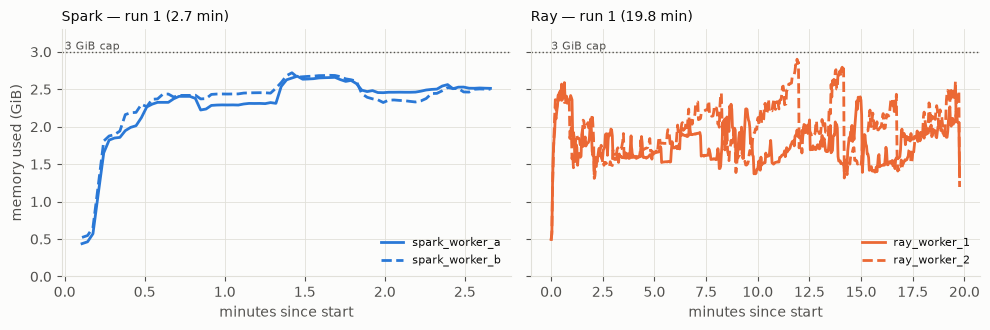

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, eng in zip(axes, ["spark", "ray"]):
    r = runs[runs.engine == eng].iloc[0]
    t0 = pd.Timestamp(r["run_ts"], tz=RUN_TZ[r["engine"]]).timestamp()
    w = stats[(stats.engine == eng) & (stats.role == "worker") & stats.timestamp.between(t0, t0 + r["total"])]
    for (c, g), ls in zip(w.groupby("container"), ["-", "--"]):
        ax.plot((g.timestamp - t0) / 60, g.mem_gib, color=COLORS[eng], lw=2, ls=ls, label=c)
    ax.axhline(3.0, color=INK2, lw=1, ls=":"); ax.text(0, 3.03, "3 GiB cap", fontsize=8, color=INK2)
    ax.set_title(f"{eng.capitalize()} — run 1 ({r['total']/60:.1f} min)", loc="left", fontsize=10)
    ax.set_xlabel("minutes since start"); ax.legend(frameon=False, fontsize=8, loc="lower right")
axes[0].set_ylabel("memory used (GiB)"); axes[0].set_ylim(0, 3.3)
fig.tight_layout(); fig.savefig("report/figures/fig3_worker_memory.png", dpi=200); plt.show()

### Figure 4 — Worker CPU during run 1 (2 cores = 200 %)
Thick line: 30-second rolling average; faint line: raw ~2 s samples.

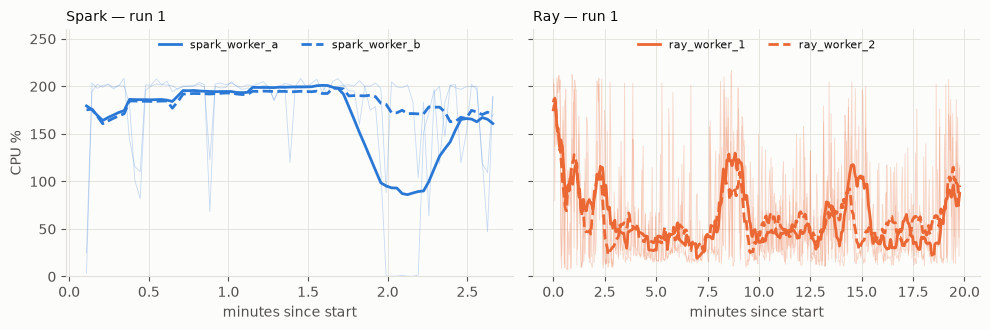

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, eng in zip(axes, ["spark", "ray"]):
    r = runs[runs.engine == eng].iloc[0]
    t0 = pd.Timestamp(r["run_ts"], tz=RUN_TZ[r["engine"]]).timestamp()
    w = stats[(stats.engine == eng) & (stats.role == "worker") & stats.timestamp.between(t0, t0 + r["total"])]
    for (c, g), ls in zip(w.groupby("container"), ["-", "--"]):
        m = (g.timestamp - t0) / 60
        ax.plot(m, g.cpu_percent, color=COLORS[eng], lw=0.6, alpha=0.25)
        ax.plot(m, g.cpu_percent.rolling(15, min_periods=1, center=True).mean(), color=COLORS[eng], lw=2, ls=ls, label=c)
    ax.set_title(f"{eng.capitalize()} — run 1", loc="left", fontsize=10)
    ax.set_xlabel("minutes since start"); ax.legend(frameon=False, fontsize=8, loc="upper center", ncol=2)
axes[0].set_ylabel("CPU %"); axes[0].set_ylim(0, 260)
fig.tight_layout(); fig.savefig("report/figures/fig4_worker_cpu.png", dpi=200); plt.show()

## 4. Pipeline parity — are the two outputs identical?

In [9]:
print(subprocess.run(["python", "compare_outputs.py"], capture_output=True, text=True).stdout)

Pipeline parity: Spark output vs Ray output

  [MATCH]  same column names
  [MATCH]  row count  spark=17,865,181  ray=17,865,181
  [MATCH]  sum(passenger_count)  spark=23805095.00  ray=23805095.00
  [MATCH]  sum(trip_distance)  spark=60134887.92  ray=60134887.92
  [MATCH]  sum(fare_amount)  spark=343042959.25  ray=343042959.25
  [MATCH]  sum(tip_amount)  spark=64153700.93  ray=64153700.93
  [MATCH]  sum(total_amount)  spark=506959678.49  ray=506959678.49
  [MATCH]  sum(duration_sec)  spark=17418775116.00  ray=17418775116.00
  [MATCH]  sum(speed_mph)  spark=197088783.64  ray=197088783.64
  [MATCH]  row-multiset fingerprint  spark=14672325616244656533  ray=14672325616244656533
  [MATCH]  avg_speed_hour, 24 hours, max abs difference = 0.000000 (tolerance 0.001)

RESULT: MATCH -- identical outputs

